# 02 Models, priors, prior predictive checks and MCMC fitting

This notebook goes with the report sections on the models, the priors, the model code and the inference details. All MCMC output is saved to results/*.nc, so notebook 03 (diagnostics, checks, comparison, results) can be rerun without refitting.

We use Bambi (a formula interface on top of PyMC) and ArviZ for diagnostics. 

Each hierarchical model takes a few minutes on a laptop. While developing, you can switch off the extra fits (prior sensitivity, leave-future-out, spline) with the flags below.

In [1]:
RUN_MAIN = True          # M0-M3 on the main data
RUN_SENSITIVITY = True   # refits with all prior scales x0.5 and x2 (required: prior sensitivity)
RUN_LFO = True           # leave-future-out: fit on seasons <= 2005, predict 2006-2026
RUN_SPLINE = True        # nonlinear trend without a fixed breakpoint (extension)
FORCE_REFIT = False      # True = ignore saved results and refit

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
import bambi as bmb
import pymc as pm

import icebreak_common as ic

print("bambi", bmb.__version__, "| pymc", pm.__version__, "| arviz", az.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

d = ic.load_breakup(recent_only=True)
print(f"{len(d):,} break-up observations, {d.site.nunique()} sites, {d.season.nunique()} seasons, "
      f"{d.season_region.nunique()} season-region cells")

bambi 0.15.0 | pymc 5.25.1 | arviz 0.23.4
6,093 break-up observations, 64 sites, 127 seasons, 355 season-region cells


## Observation model and the four models

The outcome $y_{st}$ is the break-up day of year (SYKE code 28) at site $s$ in season $t$. The residuals have heavier tails than a normal distribution (notebook 01, Fig. 5), so every model uses a Student-t observation model:

$$y_{st} \sim \text{Student-t}(\nu,\ \mu_{st},\ \sigma)$$

Predictors: $\text{lat}_s$ = latitude − 62.98°, $\text{lon}_s$ = longitude − 26°, $x_t$ = (year − 1990)/10 (decades), $p_t = \max(\text{year} − 1980, 0)/10$.

| Model | Linear predictor $\mu_{st}$ | Purpose |
|---|---|---|
| M0 pooled | $\alpha + \beta_{lat}\text{lat}_s + \beta_{lon}\text{lon}_s + \beta_x x_t$ | Baseline, no grouping |
| M1 hierarchical, linear trend | M0 $+\ \gamma\,\text{lat}_s x_t + a_s + b_s x_t + u_t$ | H1, average trend, H3 |
| M2 hierarchical, broken stick | M1 $+\ \beta_p p_t$ | H2: trend changes after 1980 |
| M3 M2 + regional year effects | M2 $+\ v_{t,r(s)}$ | Weather varies between south, central and north |

The group-level parts:
- $a_s \sim N(0, \tau_a)$ and $b_s \sim N(0, \tau_b)$ give each lake its own level and trend. Bambi treats them as independent, so there is no correlation parameter.
- $u_t \sim N(0, \tau_u)$ is a crossed year effect shared by all lakes, since a warm or cold spring moves every lake at once. Without it the ~50 lakes in a year would count as independent evidence and the trend would look much more certain than it is.
- $v_{t,r} \sim N(0, \tau_v)$ (M3 only) adds a year effect for each of three latitude regions (south < 62.5° N ≤ central < 65° N ≤ north).

In M2 and M3, $\beta_x$ is the trend before 1980 and $\beta_x + \beta_p$ the trend after 1980, both in days per decade at latitude 62.98°. The coefficient $\gamma$ lets the trend depend on latitude (H3).

## Priors

Every prior is proper and set by us; no Bambi defaults are left. The priors are weakly informative. They rule out impossible values such as break-up in winter or autumn, but are much wider than the effects we expect.

| Parameter | Prior | Reasoning |
|---|---|---|
| $\alpha$ (Intercept) | $N(130, 15)$ | Ice in central Finland breaks up around mid-May (day ~135); ±2 SD covers April to mid-June |
| $\beta_{lat}$ | $N(0, 5)$ days/° | From the south coast to Lapland (~9°) the difference is about 5-6 weeks, a few days per degree. Centred at 0 so the prior does not assume H1 |
| $\beta_{lon}$ | $N(0, 3)$ days/° | Continentality might matter a little; centred at 0 |
| $\beta_x$ | $N(0, 2)$ days/decade | Climate trends are a few days per decade, so ±4 days/decade is generous |
| $\beta_p$ | $N(0, 3)$ days/decade | Change in slope after 1980, same order of magnitude |
| $\gamma$ | $N(0, 0.5)$ days/decade per ° | Over 9° this allows trends that differ by several days/decade |
| $\tau_a$ | Half-$N(0, 10)$ days | Lakes at the same latitude differ by days up to a couple of weeks |
| $\tau_b$ | Half-$N(0, 1)$ days/decade | Lake trends should differ by at most a couple of days/decade |
| $\tau_u$ | Half-$N(0, 10)$ days | Weather shifts break-up by one to two weeks from year to year |
| $\tau_v$ | Half-$N(0, 5)$ days | Regional deviations from the national year effect are smaller |
| $\sigma$ | Half-$N(0, 10)$ days | The remaining lake-year noise is a few days |
| $\nu$ | Gamma(2, 0.1) | Mean 20, so both heavy tails ($\nu<5$) and near-normal data ($\nu>30$) are possible. Same as the brms default |

The prior predictive check below shows these priors give plausible break-up dates.

In [3]:
prior_table = pd.DataFrame(
    [(k, v[0], v[1], v[2]) for k, v in ic.PRIOR_SPEC.items()],
    columns=["term", "distribution", "mean / alpha", "scale / beta"])
prior_table

,term,distribution,mean / alpha,scale / beta
0,Intercept,Normal,130.0,15.0
1,lat_c,Normal,0.0,5.0
2,lon_c,Normal,0.0,3.0
3,decade_c,Normal,0.0,2.0
4,post1980,Normal,0.0,3.0
5,lat_c:decade_c,Normal,0.0,0.5
6,1|site,HalfNormal,NaN,10.0
7,decade_c|site,HalfNormal,NaN,1.0
8,1|season_f,HalfNormal,NaN,10.0
9,1|season_region,HalfNormal,NaN,5.0


## Code for the models
The formulas and priors are in icebreak_common.py (FORMULAS, PRIOR_SPEC, make_priors, build_model), so all notebooks use the same models. Printing a Bambi model lists its priors, which lets us check that no defaults are left. This is just a lifesaver.

In [4]:
for name, f in ic.FORMULAS.items():
    print(f"{name}:\n    {f}")

models = {name: ic.build_model(name, d) for name in ic.FORMULAS}
print(models["M3_hier_broken_region"])

M0_pooled:
    breakup_doy ~ lat_c + lon_c + decade_c
M1_hier_linear:
    breakup_doy ~ lat_c + lon_c + decade_c + lat_c:decade_c + (1 + decade_c | site) + (1 | season_f)
M2_hier_broken:
    breakup_doy ~ lat_c + lon_c + decade_c + post1980 + lat_c:decade_c + (1 + decade_c | site) + (1 | season_f)
M3_hier_broken_region:
    breakup_doy ~ lat_c + lon_c + decade_c + post1980 + lat_c:decade_c + (1 + decade_c | site) + (1 | season_f) + (1 | season_region)
       Formula: breakup_doy ~ lat_c + lon_c + decade_c + post1980 + lat_c:decade_c + (1 + decade_c | site) + (1 | season_f) + (1 | season_region)
        Family: t
          Link: mu = identity
  Observations: 6093
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 130.0, sigma: 15.0)
            lat_c ~ Normal(mu: 0.0, sigma: 5.0)
            lon_c ~ Normal(mu: 0.0, sigma: 3.0)
            decade_c ~ Normal(mu: 0.0, sigma: 2.0)
            post1980 ~ Normal(mu: 0.0, sigma: 3.0)
            la

In [5]:
for m in models.values():
    m.build()

## Prior predictive checks
For each model we draw from the prior predictive distribution using the real design (same sites, latitudes and years) and compare it with the observed break-up dates.

In [6]:
prior_pred = {}
for name, m in models.items():
    pp = m.prior_predictive(draws=500, random_seed=1)
    prior_pred[name] = pp.prior_predictive[ic.RESPONSE].values.ravel()

y = d[ic.RESPONSE].to_numpy()
rows = []
for name, yp in prior_pred.items():
    rows.append({"model": name,
                 "2.5%": np.percentile(yp, 2.5), "50%": np.percentile(yp, 50),
                 "97.5%": np.percentile(yp, 97.5),
                 "share before 1 Feb or after 1 Aug": np.mean((yp < 32) | (yp > 213))})
pd.DataFrame(rows).round(3)

Sampling: [Intercept, breakup_doy, decade_c, lat_c, lon_c, nu, sigma]
Sampling: [1|season_f_offset, 1|season_f_sigma, 1|site_offset, 1|site_sigma, Intercept, breakup_doy, decade_c, decade_c|site_offset, decade_c|site_sigma, lat_c, lat_c:decade_c, lon_c, nu, sigma]
Sampling: [1|season_f_offset, 1|season_f_sigma, 1|site_offset, 1|site_sigma, Intercept, breakup_doy, decade_c, decade_c|site_offset, decade_c|site_sigma, lat_c, lat_c:decade_c, lon_c, nu, post1980, sigma]
Sampling: [1|season_f_offset, 1|season_f_sigma, 1|season_region_offset, 1|season_region_sigma, 1|site_offset, 1|site_sigma, Intercept, breakup_doy, decade_c, decade_c|site_offset, decade_c|site_sigma, lat_c, lat_c:decade_c, lon_c, nu, post1980, sigma]


,model,2.5%,50%,97.5%,share before 1 Feb or after 1 Aug
0,M0_pooled,81.981,128.968,175.446,0.002
1,M1_hier_linear,73.909,129.129,184.382,0.004
2,M2_hier_broken,73.774,130.241,186.819,0.007
3,M3_hier_broken_region,72.969,130.233,187.511,0.007


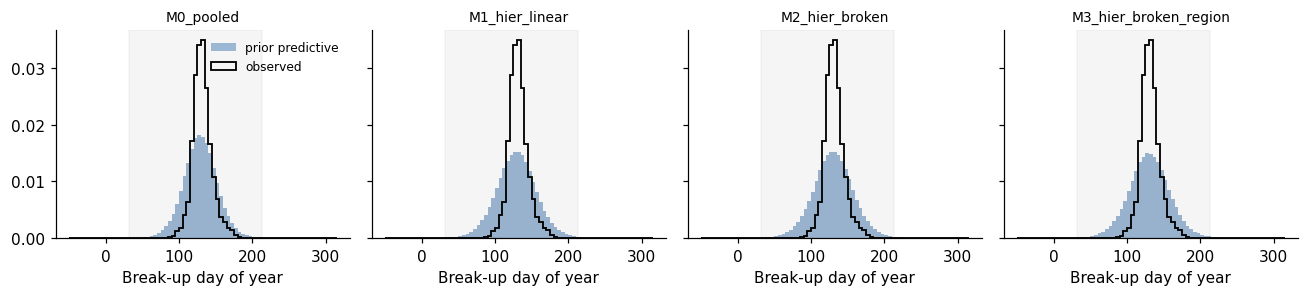

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
bins = np.arange(-50, 320, 5)
for ax, (name, yp) in zip(axes, prior_pred.items()):
    ax.hist(yp, bins=bins, density=True, color="#9bb7d4", label="prior predictive")
    ax.hist(y, bins=bins, density=True, histtype="step", color="k", lw=1.2, label="observed")
    ax.axvspan(32, 213, color="grey", alpha=0.08)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Break-up day of year")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig6_prior_predictive.png", bbox_inches="tight")
plt.show()

The prior predictive distributions are centred on spring and cover the observed dates (day 73-181). Only about 1-2 % of the mass falls outside February-July, so the priors are wide but still rule out break-up in midwinter.

## Inference details
- We sample with NUTS in PyMC (through Bambi), using 4 chains with 1000 warm-up and 1000 sampling iterations each. The resulting 4000 draws per model give enough effective sample size for the summaries and for PSIS-LOO.
- target_accept is 0.95 instead of the default 0.8. Hierarchical models whose group SDs may be small can produce divergences, and a higher target acceptance means smaller steps. Bambi's default non-centred parametrisation of group effects also helps here.
- We store the pointwise log-likelihood for PSIS-LOO.

The sampling command (wrapped in ic.fit_or_load):
```python
idata = model.fit(draws=1000, tune=1000, chains=4, cores=4, target_accept=0.95,
                  random_seed=2026, idata_kwargs={"log_likelihood": True})
```

In [8]:
print(ic.SAMPLE_KW)

idatas = {}
if RUN_MAIN:
    for name, m in models.items():
        t0 = time.time()
        idatas[name] = ic.fit_or_load(m, ic.RES_DIR / f"{name}.nc", force=FORCE_REFIT)
        n_div = int(idatas[name].sample_stats["diverging"].sum())
        print(f"{name}: done in {time.time() - t0:.0f} s, divergences = {n_div}")

{'draws': 1000, 'tune': 1000, 'chains': 4, 'cores': 4, 'target_accept': 0.95, 'random_seed': 2026}
M0_pooled: done in 0 s, divergences = 0
M1_hier_linear: done in 0 s, divergences = 0


/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, decade_c, post1980, lat_c:decade_c, 1|site_sigma, 1|site_offset, decade_c|site_sigma, decade_c|site_offset, 1|season_f_sigma, 1|season_f_offset]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: 

Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 284 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


M2_hier_broken: done in 295 s, divergences = 0


/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, decade_c, post1980, lat_c:decade_c, 1|site_sigma, 1|site_offset, decade_c|site_sigma, decade_c|site_offset, 1|season_f_sigma, 1|season_f_offset, 1|season_region_sigma, 1|season_region_offset]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-p

Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 470 seconds.


M3_hier_broken_region: done in 490 s, divergences = 0


A quick look at convergence. The full diagnostics are in notebook 03.

In [9]:
if idatas:
    display(pd.DataFrame({k: ic.diagnostics_table(v) for k, v in idatas.items()}).T.round(3))

,max R-hat,min bulk-ESS,min tail-ESS,divergences,parameters
M0_pooled,1.00,2432.0,2454.0,0.0,6.0
M1_hier_linear,1.10,31.0,112.0,0.0,520.0
M2_hier_broken,1.02,203.0,275.0,0.0,521.0
M3_hier_broken_region,1.00,1147.0,1841.0,0.0,1232.0


## Prior sensitivity refits
We multiply every prior scale by 0.5 (tighter) and by 2 (wider). This covers the SDs of the coefficient priors, the half-normal scales of the group SDs and of $\sigma$, and the mean of the $\nu$ prior. If the conclusions stay the same, they come from the data rather than from our prior choices. 

In [10]:
SENS_SCALES = [0.5, 2.0]
if RUN_SENSITIVITY:
    for name in ic.FORMULAS:
        for sc in SENS_SCALES:
            m = ic.build_model(name, d, prior_scale=sc)
            t0 = time.time()
            idt = ic.fit_or_load(m, ic.RES_DIR / f"{name}_prior{sc}.nc", force=FORCE_REFIT)
            print(f"{name} prior x{sc}: {time.time() - t0:.0f} s, "
                  f"divergences = {int(idt.sample_stats['diverging'].sum())}")

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, decade_c]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 14 seconds.


M0_pooled prior x0.5: 27 s, divergences = 0


/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, decade_c]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


... (30 outputs left out)

Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 452 seconds.


M3_hier_broken_region prior x2.0: 465 s, divergences = 0


## Leave-future-out fits (predictive check for RQ2)
PSIS-LOO leaves out one lake-year at a time, and the other lakes in that year then reveal the year's weather, which makes the prediction easy. For RQ2 we care about years the model has never seen, so we also fit each model to seasons up to 2005 and evaluate the log predictive density on 2006-2026 in notebook 03.

In [11]:
LFO_SPLIT = 2005
d_train = d[d.season <= LFO_SPLIT].reset_index(drop=True)
print(f"training rows: {len(d_train):,}, test rows: {(d.season > LFO_SPLIT).sum():,}")
if RUN_LFO:
    for name in ic.FORMULAS:
        m = ic.build_model(name, d_train)
        t0 = time.time()
        idt = ic.fit_or_load(m, ic.RES_DIR / f"{name}_lfo{LFO_SPLIT}.nc", force=FORCE_REFIT)
        print(f"{name} LFO: {time.time() - t0:.0f} s, "
              f"divergences = {int(idt.sample_stats['diverging'].sum())}")

training rows: 4,950, test rows: 1,143


/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, decade_c]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.


M0_pooled LFO: 22 s, divergences = 0


... (11 outputs left out)

Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 455 seconds.


M3_hier_broken_region LFO: 466 s, divergences = 0


## Extension: spline trend instead of a fixed breakpoint
In M2 and M3 we chose the 1980 breakpoint by hand. To check that choice, M3s replaces the linear and broken-stick terms with a cubic B-spline of the year (8 basis functions; the first is dropped so the Intercept is the 1900 level). The spline coefficients get $N(0, 10)$ priors in days, and all other priors are as in M3. If the spline bends near 1980 and its LOO is close to M3's, the simpler broken stick is a fair summary.

In [12]:
if RUN_SPLINE:
    d_s = d.copy()
    s_names = ic.add_spline_basis(d_s)
    m_s = bmb.Model(ic.spline_formula(s_names), d_s, family="t",
                    priors=ic.spline_priors(s_names), center_predictors=False)
    print(m_s)
    t0 = time.time()
    idt = ic.fit_or_load(m_s, ic.RES_DIR / "M3s_spline.nc", force=FORCE_REFIT)
    print(f"M3s: {time.time() - t0:.0f} s, divergences = {int(idt.sample_stats['diverging'].sum())}")

       Formula: breakup_doy ~ lat_c + lon_c + s1 + s2 + s3 + s4 + s5 + s6 + s7 + lat_c:decade_c + (1 + decade_c | site) + (1 | season_f) + (1 | season_region)
        Family: t
          Link: mu = identity
  Observations: 6093
        Priors: 
    target = mu
        Common-level effects
            Intercept ~ Normal(mu: 130.0, sigma: 15.0)
            lat_c ~ Normal(mu: 0.0, sigma: 5.0)
            lon_c ~ Normal(mu: 0.0, sigma: 3.0)
            s1 ~ Normal(mu: 0.0, sigma: 10.0)
            s2 ~ Normal(mu: 0.0, sigma: 10.0)
            s3 ~ Normal(mu: 0.0, sigma: 10.0)
            s4 ~ Normal(mu: 0.0, sigma: 10.0)
            s5 ~ Normal(mu: 0.0, sigma: 10.0)
            s6 ~ Normal(mu: 0.0, sigma: 10.0)
            s7 ~ Normal(mu: 0.0, sigma: 10.0)
            lat_c:decade_c ~ Normal(mu: 0.0, sigma: 0.5)
        
        Group-level effects
            1|site ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 10.0))
            decade_c|site ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 1.0))

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, sigma, Intercept, lat_c, lon_c, s1, s2, s3, s4, s5, s6, s7, lat_c:decade_c, 1|site_sigma, 1|site_offset, decade_c|site_sigma, decade_c|site_offset, 1|season_f_sigma, 1|season_f_offset, 1|season_region_sigma, 1|season_region_offset]
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(
/Users/marino/miniconda3/envs/collegeEnv/lib/python3.1

Output()

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/threadpoolctl.py:1019: RuntimeWarning: libc not found. The ctypes module in Python 3.10 is maybe too old for this OS.
  warnings.warn(


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1333 seconds.


M3s: 1349 s, divergences = 0
